# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis, **Crest** neural
crest) were scored in 02 against the shared **union** control pool and graph-smoothed. Here we render them
as deliverables and evaluate **Gate 2** — does the embryonic module pattern appear? For Maynard the pattern
is the **non-branching case**: Gast/pSom co-localise at one pole (origin) with Crest as an **inverse terminal
gradient** at the other, rather than a hub diverging into two arms. That still **passes Gate 2 (GO,
non-branching)** and leaves Gate 3 (branching-only) **NA**.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed in 02)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print('%s: %d/%d genes present' % (lab, g.size, feat[src].size))

cells: 2396 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 77/81 genes present
pSom: 91/98 genes present
Crest: 103/104 genes present


### Gate 2 — module geography on the manifold

Quantitative test of the non-branching signature for this dataset: (i) Gast and pSom **co-vary** (positive
spatial correlation) — one origin pole, not two competing arms; (ii) the dominant contrast is **pSom/Gast vs
Crest** (strong spatial anti-correlation); (iii) along pseudotime Gast and pSom decline and Crest rises
(Crest terminal); (iv) joint pSom&Crest-high cells are **depleted** — an inverse gradient, not a co-expression
hub. Crest enriches the pSom/Gast-low terminus (not the Gast pole), so **no inversion flag**.

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print('  %s vs %s: r = %+.2f' % (a,b,r))
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print('  %s: rho = %+.3f' % (s, rho))
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print('Neural-crest-high decile mean pseudotime = %.2f (terminal if ~1)' % tn[hi.values].mean())
# inverse-gradient vs co-expression-hub test
pz = (adata.obs['pSom']-adata.obs['pSom'].mean())/adata.obs['pSom'].std()
cz = (adata.obs['Crest']-adata.obs['Crest'].mean())/adata.obs['Crest'].std()
joint = ((pz>0.5)&(cz>0.5)).mean(); exp = (pz>0.5).mean()*(cz>0.5).mean()
print('joint pSom&Crest-high enrichment = %.2f (<1 = inverse gradient, not a hub)' % (joint/exp))
print('Gast/pSom co-vary (+); both oppose Crest; Crest terminal at the pSom/Gast-low pole -> no inversion flag')
print('Gate 2: single Gast/pSom -> Crest gradient + inverse terminal Crest -> GO (non-branching)')
print('Gate 3: no bifurcation -> NA')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.43
  Crest_sm vs Gast_sm: r = -0.74
  Crest_sm vs pSom_sm: r = -0.64
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.637
  pSom_sm: rho = -0.628
  Crest_sm: rho = +0.788
Neural-crest-high decile mean pseudotime = 0.83 (terminal if ~1)
joint pSom&Crest-high enrichment = 0.29 (<1 = inverse gradient, not a hub)
Gast/pSom co-vary (+); both oppose Crest; Crest terminal at the pSom/Gast-low pole -> no inversion flag
Gate 2: single Gast/pSom -> Crest gradient + inverse terminal Crest -> GO (non-branching)
Gate 3: no bifurcation -> NA


### Per-module signature figures + colorbars (deliverable)

House style: `figsize=(3.5,1.5)`, pseudotime left→right (`X_umap_lin`), `size=30`, plasma, **raw** (not
smoothed) score per cell so SmartSeq2 dropout is visible. Colorbar ticks data-driven.

<string>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar
<string>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar
<string>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar


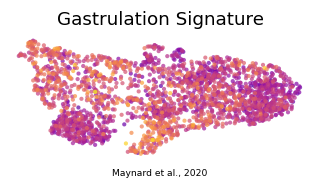

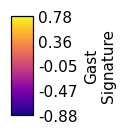

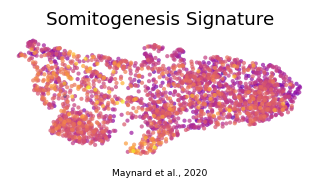

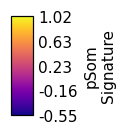

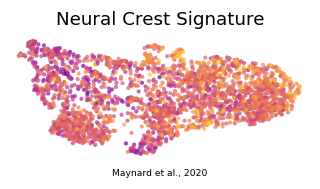

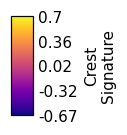

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'%s' % 'Maynard et al., 2020', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, '%s_signature.pdf' % m), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label('%s\nSignature' % m); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, '%s_colorbar.pdf' % m), bbox_inches='tight')
    print('saved', '%s_signature.pdf' % m, '+ colorbar')
    plt.show()

### Save signatures data

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (2396, 21853)
